# Часть 1. Данные и EDA

Этот ноутбук скачивает датасеты и готовит файлы для остальных частей. Повторный запуск не качает архивы заново.

Перед первым запуском в корне репозитория:

```powershell
python -m venv .venv
.venv\Scripts\activate
pip install -r requirements.txt
```

Полный прогон забирает около 7 ГБ и просит примерно 15 ГБ свободного места. Флаг `QUICK = True` ниже проверяет только `test.zip`; на нём обучать модели нельзя.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "prepare_data.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

# False — полный датасет для следующих частей.
# True — только test.zip, чтобы проверить, что ноутбук запускается.
QUICK = False

from prepare_data import prepare

summary = prepare(ROOT, quick=QUICK)


Нужно около 15 ГБ свободного места на полном прогоне. Архивы скачиваются один раз.
Проверяю AY000554/Car_plate_detecting_dataset / license.txt


c:\Projects\ПМОиНС\AI_B2B_SAAS_unicorn_startup\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Проверяю AY000554/Car_plate_detecting_dataset / README.md
Проверяю AY000554/Car_plate_detecting_dataset / train.zip
Проверяю AY000554/Car_plate_detecting_dataset / val.zip
Проверяю AY000554/Car_plate_detecting_dataset / test.zip
Проверяю AY000554/Car_plate_OCR_dataset / license.txt
Проверяю AY000554/Car_plate_OCR_dataset / README.md
Проверяю AY000554/Car_plate_OCR_dataset / train.zip
Проверяю AY000554/Car_plate_OCR_dataset / val.zip
Проверяю AY000554/Car_plate_OCR_dataset / test.zip
Распаковываю train.zip → C:\Projects\ПМОиНС\AI_B2B_SAAS_unicorn_startup\data\raw\detection\train
Распаковываю val.zip → C:\Projects\ПМОиНС\AI_B2B_SAAS_unicorn_startup\data\raw\detection\val
Уже распакован: C:\Projects\ПМОиНС\AI_B2B_SAAS_unicorn_startup\data\raw\detection\test
Распаковываю train.zip → C:\Projects\ПМОиНС\AI_B2B_SAAS_unicorn_startup\data\raw\ocr\train
Распаковываю val.zip → C:\Projects\ПМОиНС\AI_B2B_SAAS_unicorn_startup\data\raw\ocr\val
Уже распакован: C:\Projects\ПМОиНС\AI_B2B_SAAS_unicorn_st

хеши ocr: 100%|██████████| 45511/45511 [00:46<00:00, 972.74файл/s] 


Детекция: убрано точных копий файлов: 782
OCR: убрано точных копий файлов: 2
OCR: один и тот же номер был в разных выборках, перенесено файлов: 6
Считаю яркость и размытие на случайной выборке.

— Детекция: в выборку попало 24850 кадров. Битых файлов: 0, без метки: 0, с пустой меткой: 0, точных копий убрано: 782.
— Медианный кадр детекции 1200×875 px. Номер занимает около 1.09% площади.
— Один номер на кадре у 23860 из 24850 размеченных изображений.
— OCR: в выборку попало 45509 кропов, формат номера совпал у 45509. Битых файлов: 0, точных копий убрано: 2.
— Одинаковый номер встречался в разных выборках. Все его кадры собраны в одну выборку, перенесено файлов: 6.
— Следующему за детекцию: открыть configs/plates.yaml и учить YOLO. Горизонтально номера не отражать.
— Следующему за OCR: открыть data/processed/ocr/train.csv. Колонка text — номер, колонка image — путь к кропу.

Отчёт: C:\Projects\ПМОиНС\AI_B2B_SAAS_unicorn_startup\reports\part1_summary.json


## Что получилось

Ниже выводы, размеры выборок и графики. Их же можно открыть из `reports/part1_summary.json`, если ноутбук уже выполнялся.

Дальше другим людям не нужно распаковывать архивы:

- детекция читает `configs/plates.yaml`;
- OCR читает `data/processed/ocr/train.csv` (колонки `image` и `text`).


- Детекция: в выборку попало 24850 кадров. Битых файлов: 0, без метки: 0, с пустой меткой: 0, точных копий убрано: 782.
- Медианный кадр детекции 1200×875 px. Номер занимает около 1.09% площади.
- Один номер на кадре у 23860 из 24850 размеченных изображений.
- OCR: в выборку попало 45509 кропов, формат номера совпал у 45509. Битых файлов: 0, точных копий убрано: 2.
- Одинаковый номер встречался в разных выборках. Все его кадры собраны в одну выборку, перенесено файлов: 6.
- Следующему за детекцию: открыть configs/plates.yaml и учить YOLO. Горизонтально номера не отражать.
- Следующему за OCR: открыть data/processed/ocr/train.csv. Колонка text — номер, колонка image — путь к кропу.

### Детекция по выборкам

,split,files
0,train,19958
1,val,2442
2,test,2450


### OCR по выборкам

,split,files
0,train,37778
1,val,4890
2,test,2841


### Ширина кадра, детекция

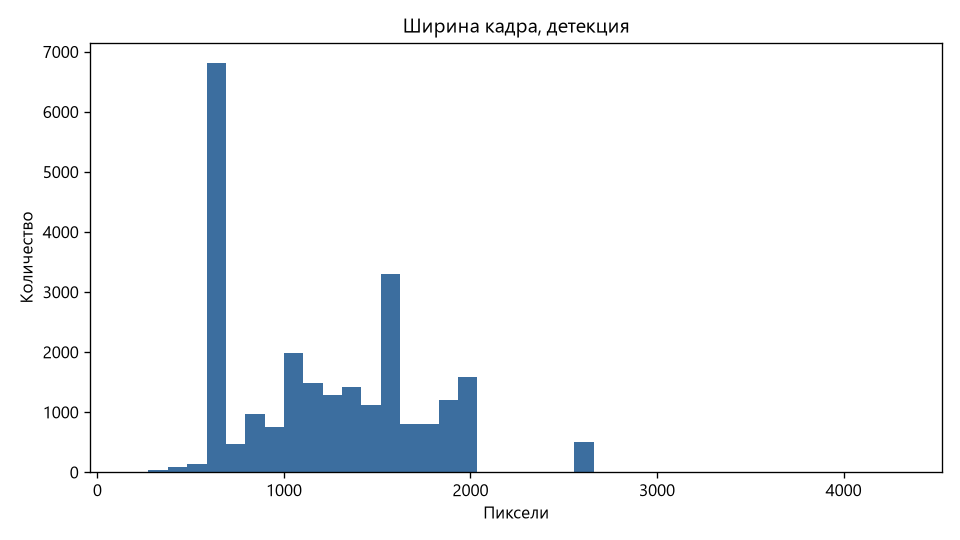

Медианная ширина кадра 1200 px, высота 875 px.

### Высота кадра, детекция

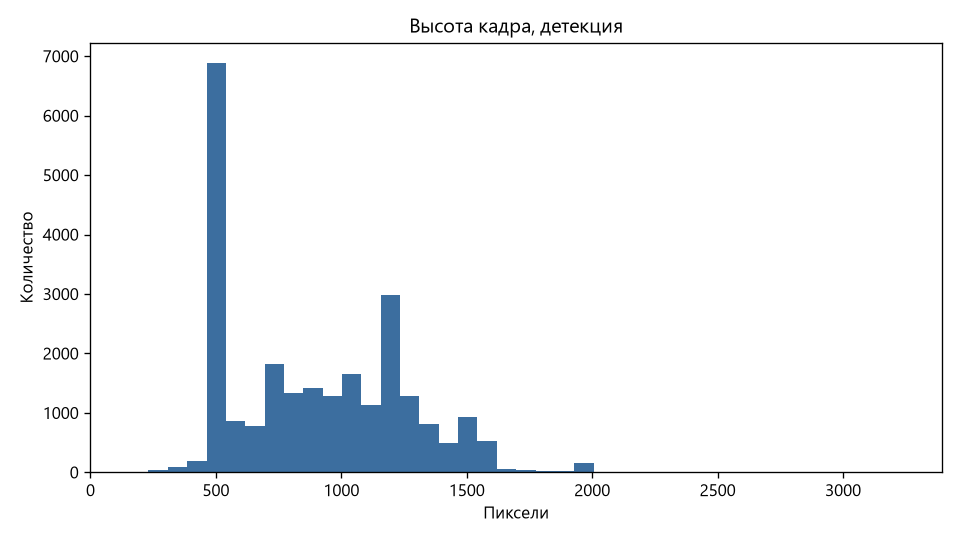

Высота кадров детекции. Модель YOLO получит кадр целиком, не кроп номера.

### Доля кадра, которую занимает номер

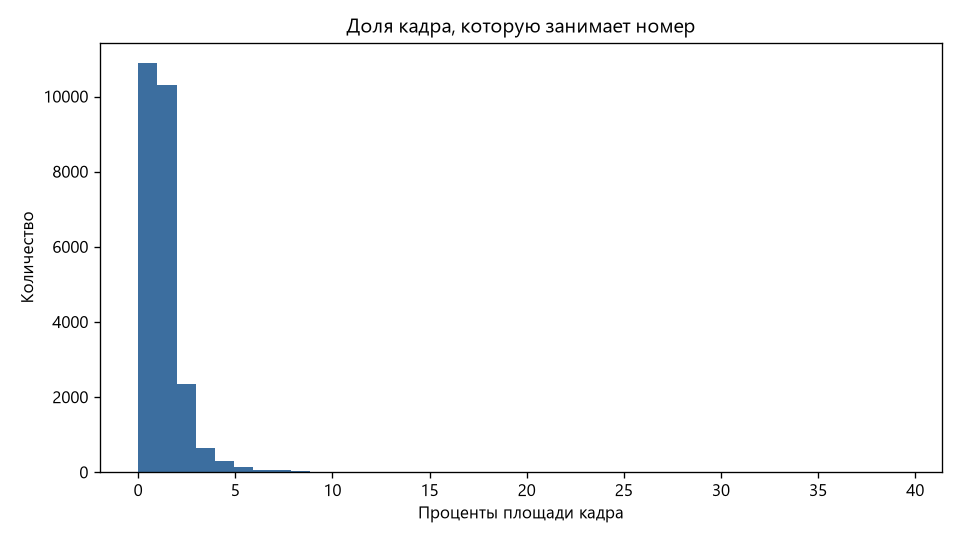

Медиана 1.09% кадра. Номер мелкий, для детекции стоит сравнить вход 640 и 960.

### Ширина кропа номера

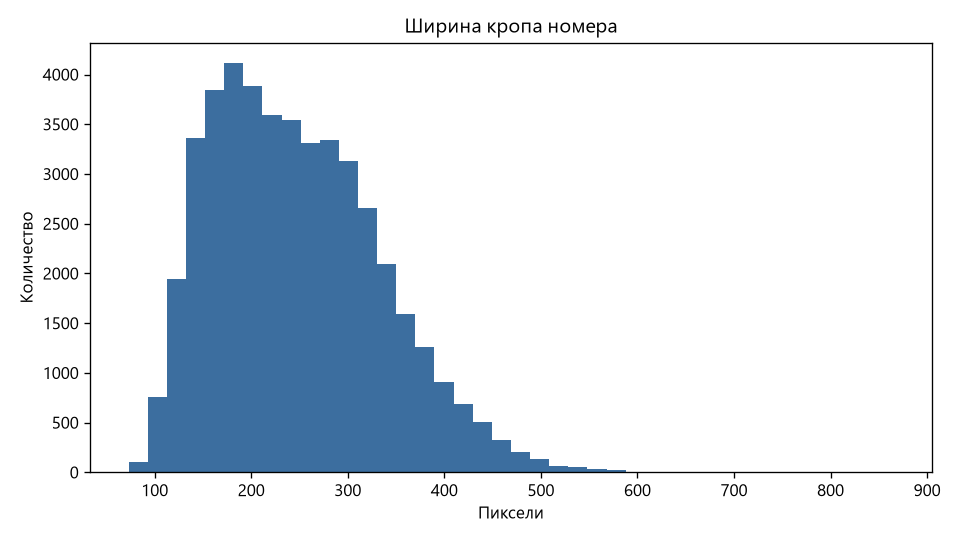

Медиана кропа 238×51 px. Кропы уже горизонтальные, поворачивать их не нужно.

### Длина строки номера

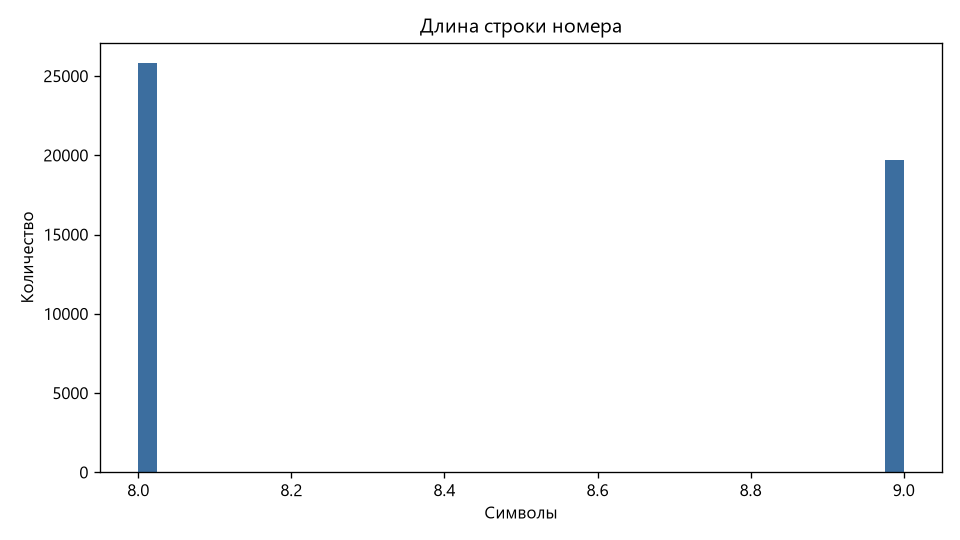

У обычного легкового номера 8 символов, у трёхзначного региона — 9.

### Частоты символов на номерах

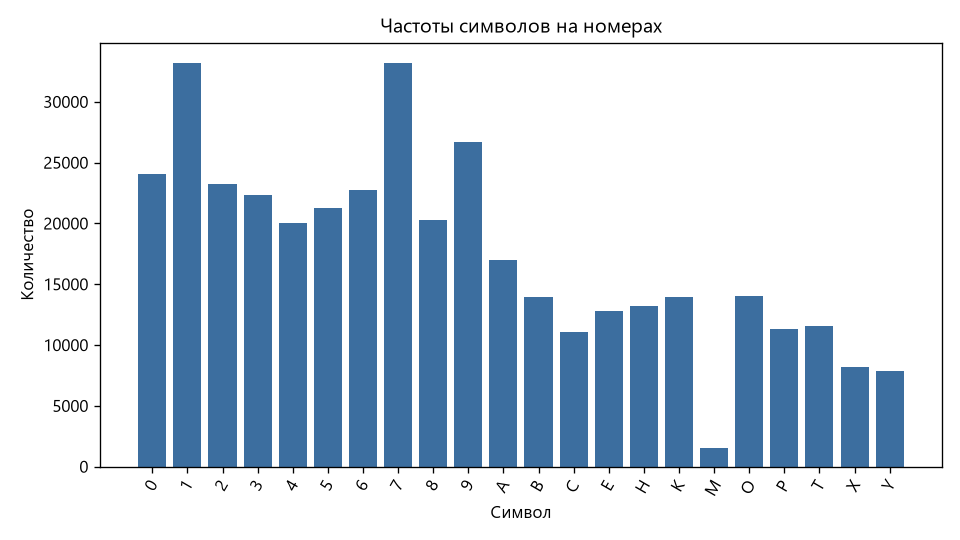

Алфавит датасета: цифры и латинские буквы ABEKMHOPCTYX.

### 15 самых частых кодов региона

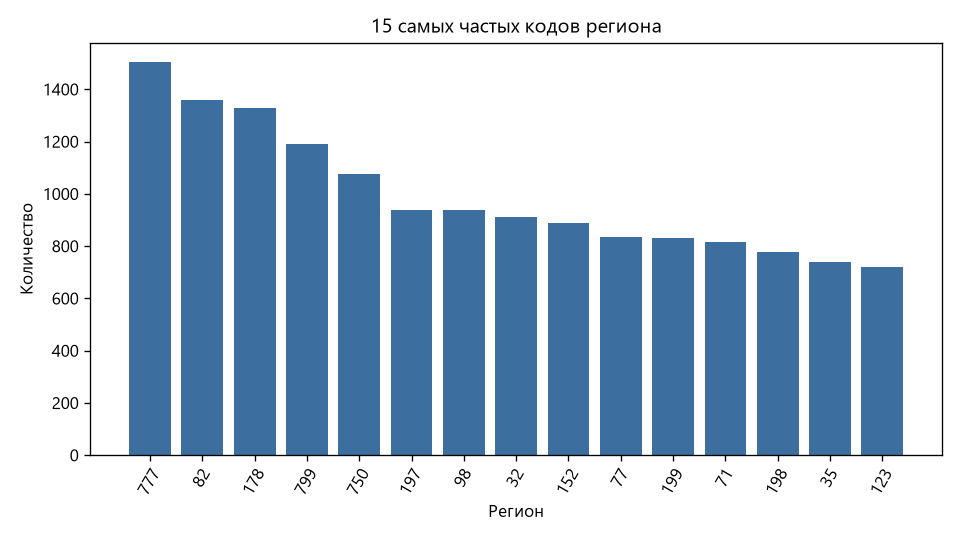

Код региона — последние 2 или 3 цифры номера. На графике только 15 лидеров.

### Яркость кадров детекции

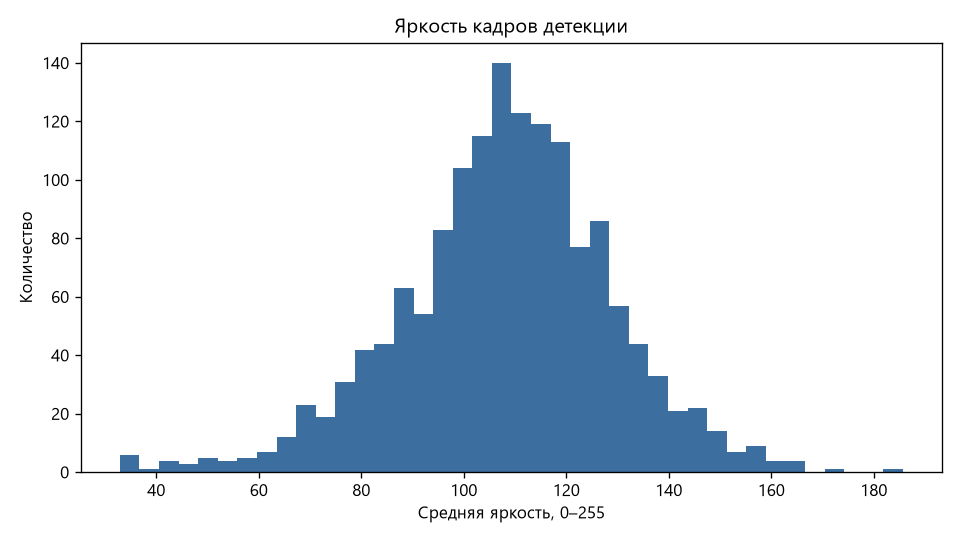

Оценка по случайным 1500 кадрам. Медиана яркости 108.9.

### Резкость кадров детекции

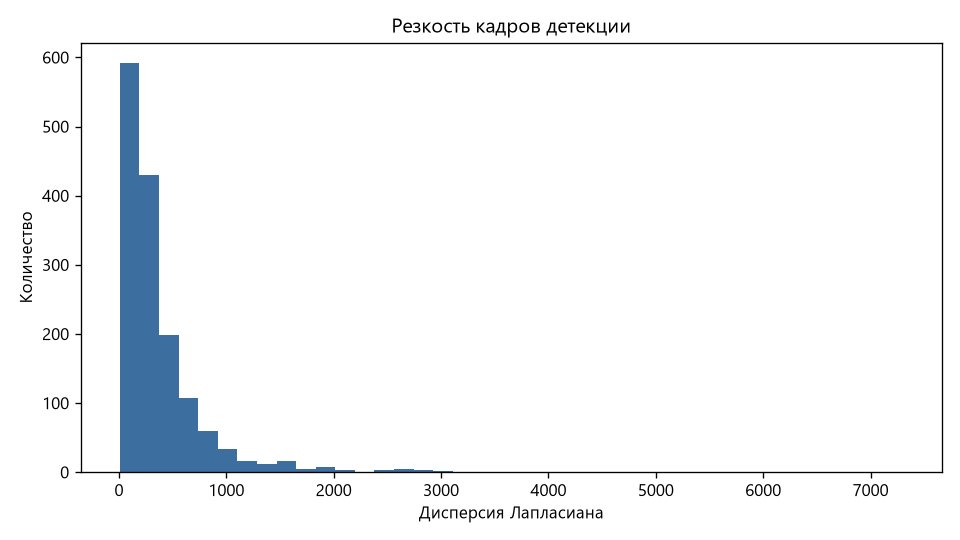

Меньшее значение — более размытый кадр. Это оценка на выборке, не на каждом файле.

### Яркость кропов OCR

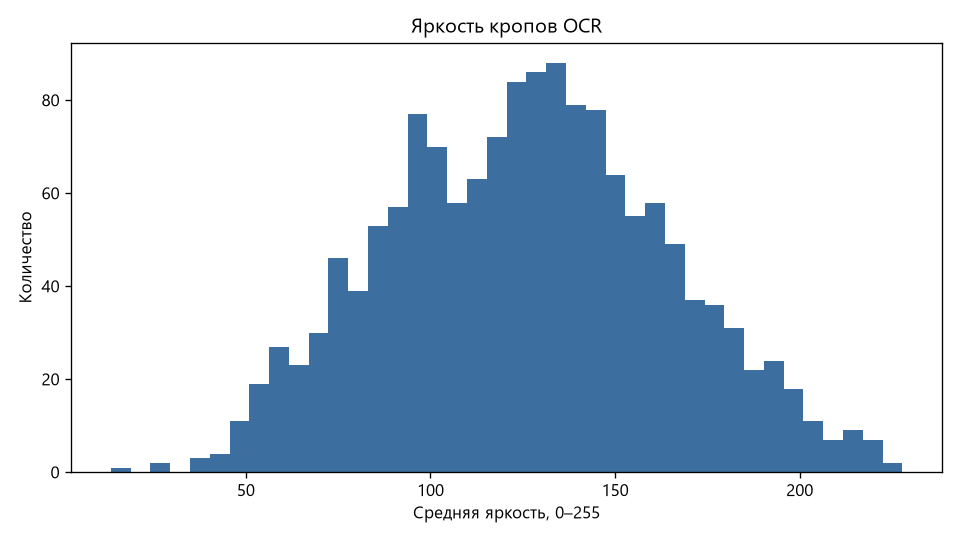

Оценка по случайным 1500 кропам. Медиана яркости 126.5.

YAML для YOLO: C:\Projects\ПМОиНС\AI_B2B_SAAS_unicorn_startup\configs\plates.yaml
CSV для OCR: C:\Projects\ПМОиНС\AI_B2B_SAAS_unicorn_startup\data\processed\ocr\all.csv


In [2]:
import json

import pandas as pd
from IPython.display import Image, Markdown, display

summary_file = ROOT / "reports" / "part1_summary.json"
if not summary_file.exists():
    raise FileNotFoundError("Сначала выполните ячейку подготовки выше.")
summary = json.loads(summary_file.read_text(encoding="utf-8"))

display(Markdown("\n".join(f"- {line}" for line in summary["conclusions"])))
display(Markdown("### Детекция по выборкам"))
display(pd.DataFrame(summary["tables"]["detection_splits"]))
display(Markdown("### OCR по выборкам"))
display(pd.DataFrame(summary["tables"]["ocr_splits"]))

for plot in summary["plots"]:
    display(Markdown(f"### {plot['title']}"))
    display(Image(filename=plot["path"]))
    display(Markdown(plot["reading"]))

print("YAML для YOLO:", summary["outputs"]["detection_yaml"])
print("CSV для OCR:", summary["outputs"]["ocr_csv"])
